# Área afectada por un tornado con Sentinel-2

**Primer parcial, ejercicio 2.** Fundamentos del Procesamiento Digital de Imágenes. Brian Aranda.

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/BrianAranda/Informes_FDPI/blob/parcial-bea/code/ejercicio_2/tornado.ipynb)

Se tienen dos imágenes Sentinel-2 del norte de Misiones, una antes y otra después del paso de un tornado. La zona incluye parte de un área urbana y una porción extensa de una reserva. Se busca mostrar el área afectada a un público no experto (punto a) y estimar su superficie, separando la reserva del área urbana (punto b).

## 1. Configuración

### Ejecución en Google Colab

En Colab la celda siguiente clona el repositorio y se ubica en `code/ejercicio_2/`. En una ejecución local no hace nada.

In [21]:
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    RAMA = "parcial-bea"
    REPO = "https://github.com/BrianAranda/Informes_FDPI.git"
    DESTINO = "/content/Informes_FDPI"
    if not os.path.isdir(DESTINO):
        subprocess.run(["git", "clone", "--depth", "1", "--branch", RAMA, REPO, DESTINO], check=True)
    os.chdir(f"{DESTINO}/code/ejercicio_2")
    print("Trabajando en", os.getcwd())

Trabajando en /content/Informes_FDPI/code/ejercicio_2


### Librerías y datos

Las imágenes no están en el repositorio. Si faltan, se descargan de la [carpeta de Drive de la cátedra](https://drive.google.com/drive/folders/18LWWn0aVPerPZURxRH59C4T446qq7Rx1).

In [22]:
import json
import urllib.parse
import urllib.request
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import tifffile
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from matplotlib.ticker import FuncFormatter
from scipy import ndimage as ndi
from skimage.filters import threshold_otsu
from skimage.morphology import disk

DIR_DATOS = Path("datos")              # no se sube al repositorio
DIR_FIG = Path("../../img/ejercicio_2")
DIR_FIG.mkdir(parents=True, exist_ok=True)

EXPORTAR_FIGURAS = False   # True solo para regenerar las figuras del informe
FORMATO_FIGURAS = "pdf"
FIGURAS_INFORME = {"muestras", "antes_despues", "firmas", "separabilidad",
                   "composiciones", "histograma_umbral", "mapa_afectado"}

# Archivos de la carpeta de Drive (nombre del zip: ID)
ESCENAS = {"20260903": "13zYGFbietnj5GP1ysYniUr6hoqsKSHou",
           "20260916": "15ppsTQ-Qre9-HigwNmhBZbD3Yj7XyzpE"}
FECHAS = {"20260903": "03/09/2026", "20260916": "16/09/2026"}


def preparar_escena(fecha):
    carpeta = DIR_DATOS / fecha
    if carpeta.is_dir():
        return carpeta
    DIR_DATOS.mkdir(exist_ok=True)
    archivo = DIR_DATOS / f"{fecha}.zip"
    if not archivo.exists():
        import gdown
        gdown.download(id=ESCENAS[fecha], output=str(archivo), quiet=False)
    with zipfile.ZipFile(archivo) as z:
        z.extractall(carpeta)
    return carpeta

### Figuras

In [23]:
from matplotlib.transforms import Bbox

%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 85}}

ANCHO = 469.47049 / 72.27   # \linewidth del informe en pulgadas


def ancho(fraccion=1.0):
    return fraccion * ANCHO


plt.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix", "grid.alpha": 0.4,
    "font.size": 11, "axes.labelsize": 11, "axes.titlesize": 11,
    "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 11,
    "figure.figsize": (ANCHO, 4), "figure.dpi": 120,
    "savefig.dpi": 300, "savefig.format": "pdf", "savefig.pad_inches": 0.02,
    "figure.constrained_layout.use": True,
    "figure.constrained_layout.w_pad": 0.02, "figure.constrained_layout.h_pad": 0.02,
    "figure.constrained_layout.wspace": 0.02, "figure.constrained_layout.hspace": 0.02,
})


def guardar(fig, nombre, margen=0.02):
    # Exporta sin títulos y con el ancho exacto. Solo recorta arriba y abajo.
    if not EXPORTAR_FIGURAS or nombre not in FIGURAS_INFORME:
        return
    titulos = [ax.get_title() for ax in fig.axes]
    for ax in fig.axes:
        ax.set_title("")
    fig.canvas.draw()
    contenido = fig.get_tightbbox(fig.canvas.get_renderer())
    caja = Bbox.from_extents(0, contenido.y0 - margen, fig.get_figwidth(), contenido.y1 + margen)
    fig.savefig(DIR_FIG / f"{nombre}.{FORMATO_FIGURAS}", bbox_inches=caja,
                metadata={"CreationDate": None} if FORMATO_FIGURAS == "pdf" else None)
    for ax, titulo in zip(fig.axes, titulos):
        ax.set_title(titulo)


def coma(ax, eje="x", decimales=2):
    # Números con coma decimal en los ejes
    f = FuncFormatter(lambda v, _: f"{v:.{decimales}f}".replace(".", ","))
    (ax.xaxis if eje == "x" else ax.yaxis).set_major_formatter(f)


def mostrar_img(ax, img, letra="", rotulo="", **kwargs):
    im = ax.imshow(img, **kwargs)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel(f"({letra}) {rotulo}" if letra else rotulo)
    return im

## 2. Datos y preprocesamiento

Las imágenes son productos de nivel 2A, es decir reflectancia de superficie con corrección atmosférica. Cada banda viene en un TIFF de 2500 × 1631 píxeles, en enteros de 16 bits y en coordenadas geográficas (EPSG:4326). Todas están remuestreadas a unos 10 m, aunque B05, B06, B07, B8A, B11 y B12 se miden a 20 m y B01 y B09 a 60 m. No viene la B10.

Los valores son la reflectancia multiplicada por 65535, por eso se dividen por 65535. Se comprueba con el monte, que da valores típicos de vegetación (rojo cerca de 0,02 y NIR cerca de 0,27).

In [24]:
BANDAS = ["B01", "B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B09", "B11", "B12"]
LONGITUD_ONDA = {"B01": 443, "B02": 490, "B03": 560, "B04": 665, "B05": 705, "B06": 740,
                 "B07": 783, "B08": 842, "B8A": 865, "B09": 945, "B11": 1610, "B12": 2190}


def leer_escena(fecha):
    carpeta = preparar_escena(fecha)
    bandas = {}
    for b in BANDAS:
        ruta = next(carpeta.glob(f"*_L2A_{b}_*.tiff"))
        bandas[b] = tifffile.imread(ruta).astype(np.float32) / 65535
    return bandas, ruta


pre, ruta = leer_escena("20260903")
pos, _ = leer_escena("20260916")
H, W = pre["B04"].shape

# 0 es sin dato y 65535 es saturado
valido = np.ones((H, W), bool)
for bandas in (pre, pos):
    for b in BANDAS:
        valido &= (bandas[b] > 0) & (bandas[b] < 1)
print(f"{H} × {W} píxeles, {(~valido).sum()} no válidos")
print("Monte en la imagen anterior: rojo", round(float(np.median(pre["B04"])), 3), " NIR", round(float(np.median(pre["B08"])), 3))

1631 × 2500 píxeles, 71 no válidos
Monte en la imagen anterior: rojo 0.018  NIR 0.26


**Tamaño del píxel.** La grilla está en grados. Para pasar a metros se usa la longitud de un grado en el elipsoide WGS 84, que depende de la latitud de cada fila.

In [25]:
with tifffile.TiffFile(ruta) as t:
    geo = t.geotiff_metadata
LON0, LAT0 = geo["ModelTiepoint"][3:5]      # esquina superior izquierda
DLON, DLAT = geo["ModelPixelScale"][:2]      # grados por píxel

lat_fila = LAT0 - (np.arange(H) + 0.5) * DLAT
phi = np.radians(lat_fila)
m_lat = 111132.954 - 559.822 * np.cos(2 * phi) + 1.175 * np.cos(4 * phi)     # metros por grado de latitud
m_lon = 111412.84 * np.cos(phi) - 93.5 * np.cos(3 * phi) + 0.118 * np.cos(5 * phi)   # metros por grado de longitud
DX, DY = DLON * m_lon, DLAT * m_lat            # metros por píxel en cada fila
AREA_PX = DX * DY                              # m² por píxel en cada fila


def superficie(mascara):
    return float((mascara.sum(axis=1) * AREA_PX).sum() / 1e6)   # km²


print(f"Píxel: {DX.mean():.2f} m × {DY.mean():.2f} m = {AREA_PX.mean():.1f} m²")
print(f"Superficie de la escena: {superficie(np.ones((H, W), bool)):.1f} km²")
print(f"Extensión: longitud {LON0:.4f} a {LON0 + W * DLON:.4f}, latitud {LAT0:.4f} a {LAT0 - H * DLAT:.4f}")

Píxel: 10.06 m × 10.01 m = 100.6 m²
Superficie de la escena: 410.4 km²
Extensión: longitud -53.9576 a -53.7053, latitud -26.4621 a -26.6094


**Alineación entre fechas.** Se mide el corrimiento entre las dos imágenes con correlación de fase sobre el NIR.

In [26]:
(dx, dy), _ = cv2.phaseCorrelate(pre["B08"].astype(np.float64), pos["B08"].astype(np.float64))
print(f"Corrimiento: {dx:.2f} px en x, {dy:.2f} px en y")

Corrimiento: 0.03 px en x, 0.06 px en y


### Bitácora

| Decisión | Motivo | Criterio |
|---|---|---|
| Dividir por 65535 | La exportación de 16 bits lleva la reflectancia de 0 a 1 al rango 0 a 65535 | Valores del monte (rojo 0,02 y NIR 0,27) |
| Descartar los valores 0 y 65535 | Son sin dato o saturados | Son 71 píxeles |
| Área del píxel según la latitud | La grilla está en grados | Elipsoide WGS 84 |
| No remuestrear entre fechas | El corrimiento es menor a 0,1 px | Correlación de fase |
| No enmascarar nubes | No hay nubes en ninguna de las dos fechas | Visual |

## 3. Áreas de muestra

Se marcaron rectángulos sobre la imagen posterior en color natural, donde la traza del tornado se ve a simple vista como una franja gris dentro del monte. Una mitad se usa para elegir bandas y umbrales y la otra mitad para validar.

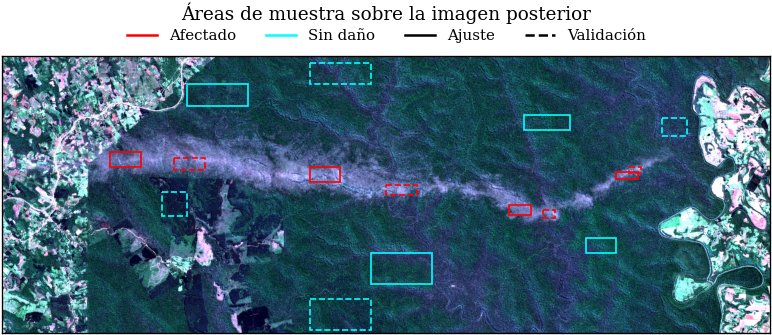

In [27]:
RGB = ("B04", "B03", "B02")
LIM = {b: np.percentile(pre[b][valido], [2, 98]) for b in RGB}   # mismo estiramiento en las dos fechas


def color_natural(bandas, ganancia=None):
    g = ganancia or {b: 1.0 for b in RGB}
    return np.dstack([np.clip((bandas[b] * g[b] - LIM[b][0]) / (LIM[b][1] - LIM[b][0]), 0, 1) for b in RGB])


# (fila inicial, fila final, columna inicial, columna final)
AFECTADO = [(670, 720, 350, 450), (720, 770, 1000, 1100), (845, 875, 1650, 1720), (735, 760, 2000, 2070)]
SIN_DANO = [(450, 520, 600, 800), (1000, 1100, 1200, 1400), (550, 600, 1700, 1850), (950, 1000, 1900, 2000)]
AFECTADO_VAL = [(690, 730, 560, 660), (780, 810, 1250, 1350), (860, 885, 1760, 1800), (720, 740, 2040, 2080)]
SIN_DANO_VAL = [(380, 450, 1000, 1200), (1150, 1250, 1000, 1200), (560, 620, 2150, 2230), (800, 880, 520, 600)]


def muestras(img, rects):
    return np.concatenate([img[f0:f1, c0:c1].ravel() for f0, f1, c0, c1 in rects])


def dibujar(ax, rects, color, estilo="-", dy=0):
    for f0, f1, c0, c1 in rects:
        ax.add_patch(Rectangle((c0, f0 - dy), c1 - c0, f1 - f0, fill=False, ec=color, lw=1, ls=estilo))


RECORTE = np.s_[450:1050, :]   # franja de la traza
fig, ax = plt.subplots(figsize=(ancho(1.0), 2.75))
ax.imshow(color_natural(pos)[360:1260])
for rects, color, estilo in ((AFECTADO, "red", "-"), (SIN_DANO, "cyan", "-"),
                             (AFECTADO_VAL, "red", "--"), (SIN_DANO_VAL, "cyan", "--")):
    dibujar(ax, rects, color, estilo, dy=360)
ax.set_xticks([])
ax.set_yticks([])
ax.legend(handles=[Line2D([], [], color="red", label="Afectado"), Line2D([], [], color="cyan", label="Sin daño"),
                   Line2D([], [], color="k", label="Ajuste"), Line2D([], [], color="k", ls="--", label="Validación")],
          loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=4, frameon=False, fontsize=9)
ax.set_title("Áreas de muestra sobre la imagen posterior", pad=22)
guardar(fig, "muestras")
plt.show()

## 4. Representación visual (punto a)

Para un público no experto se usa el color natural (bandas 4, 3 y 2), que muestra la zona como la vería una persona desde el aire. Son además las bandas de 10 m, las de mayor detalle.

Entre las dos fechas cambió la atmósfera. En el monte sin daño el azul sube un 36 % y la imagen posterior se ve azulada. Para que la diferencia de color se deba solo al daño, cada banda de la imagen posterior se multiplica por un factor que iguala el monte sin daño de las dos fechas. Después se aplica el mismo estiramiento lineal a las dos imágenes, entre los percentiles 2 y 98 de la imagen anterior.

Factor por banda: {'B04': 1.006, 'B03': 0.93, 'B02': 0.736}


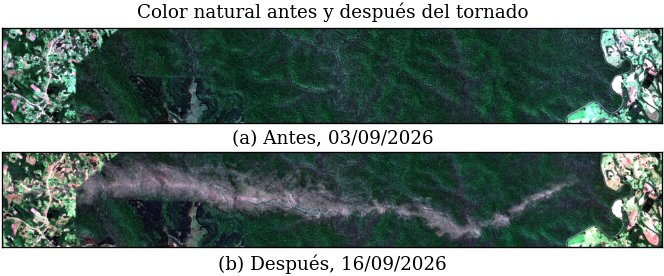

In [28]:
ganancia = {b: float(np.median(muestras(pre[b], SIN_DANO)) / np.median(muestras(pos[b], SIN_DANO))) for b in RGB}
print("Factor por banda:", {b: round(g, 3) for b, g in ganancia.items()})

natural_pre = color_natural(pre)
natural_pos = color_natural(pos, ganancia)

TRAZA = np.s_[570:930, :]   # franja donde está la traza
fig, ax = plt.subplots(2, 1, figsize=(ancho(1.0), 2.3))
mostrar_img(ax[0], natural_pre[TRAZA], "a", f"Antes, {FECHAS['20260903']}")
mostrar_img(ax[1], natural_pos[TRAZA], "b", f"Después, {FECHAS['20260916']}")
ax[0].set_title("Color natural antes y después del tornado")
guardar(fig, "antes_despues")
plt.show()

### Bitácora

| Decisión | Motivo | Criterio |
|---|---|---|
| Color natural 4-3-2 | Se interpreta sin conocimientos previos y tiene 10 m de resolución | Pedido del punto a |
| Igualar el monte sin daño entre fechas | El azul sube un 36 % por la atmósfera | Muestras sin daño |
| Mismo estiramiento en las dos fechas | Los colores se pueden comparar | Visual |
| Sin ecualización | Cambia los colores y deja de ser fiel | Visual |

## 5. Elección de bandas e índices

**Firma espectral.** Se compara la reflectancia mediana de las muestras afectadas y sin daño en las dos fechas.

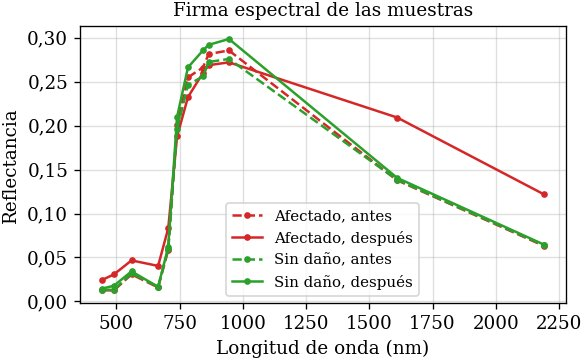

In [29]:
fig, ax = plt.subplots(figsize=(ancho(0.75), 3))
x = [LONGITUD_ONDA[b] for b in BANDAS]
for rects, color, nombre in ((AFECTADO, "tab:red", "Afectado"), (SIN_DANO, "tab:green", "Sin daño")):
    for bandas, estilo, cuando in ((pre, "--", "antes"), (pos, "-", "después")):
        y = [np.median(muestras(bandas[b], rects)) for b in BANDAS]
        ax.plot(x, y, estilo, marker="o", ms=3, color=color, label=f"{nombre}, {cuando}")
ax.set_xlabel("Longitud de onda (nm)")
ax.set_ylabel("Reflectancia")
ax.grid(True)
ax.legend(fontsize=9)
coma(ax, "y")
ax.set_title("Firma espectral de las muestras")
guardar(fig, "firmas")
plt.show()

En la zona afectada suben el rojo (B04) y los dos SWIR (B11 y B12), y el NIR queda por debajo del monte sano. Es lo que pasa cuando el dosel se rompe y quedan ramas, troncos y hojas secas a la vista. El humo o la neblina no subirían el SWIR 2, porque casi no lo afectan.

**Separabilidad.** Para cada banda e índice se calcula la razón de Fisher entre las muestras afectadas y sin daño, $F = (\mu_1 - \mu_2)^2 / (\sigma_1^2 + \sigma_2^2)$, y el solapamiento entre sus histogramas. Se compara la diferencia entre fechas con la imagen posterior sola. También se prueban los canales S de HSV y L* de Lab de la composición en color natural.

Los índices son diferencias normalizadas, $(a - b)/(a + b)$. Si la luz cambia por el relieve o por la altura del sol, las dos bandas cambian casi en la misma proporción y el índice no cambia.

In [30]:
def dif_norm(bandas, a, b):
    return (bandas[a] - bandas[b]) / (bandas[a] + bandas[b] + 1e-6)


INDICES = {"NDVI": ("B08", "B04"), "NDMI": ("B8A", "B11"), "NBR": ("B8A", "B12")}


def fisher(a, b):
    return (a.mean() - b.mean()) ** 2 / (a.var() + b.var())


def solapamiento(a, b, bins=64):
    lo, hi = min(a.min(), b.min()), max(a.max(), b.max())
    ha, _ = np.histogram(a, bins, (lo, hi))
    hb, _ = np.histogram(b, bins, (lo, hi))
    return np.minimum(ha / ha.sum(), hb / hb.sum()).sum()


variables = {}
for b in ("B04", "B08", "B8A", "B11", "B12"):
    variables[b] = (pre[b], pos[b])
for nombre, (a, b) in INDICES.items():
    variables[nombre] = (dif_norm(pre, a, b), dif_norm(pos, a, b))
hsv_pre = cv2.cvtColor((natural_pre * 255).astype(np.uint8), cv2.COLOR_RGB2HSV).astype(np.float32)
hsv_pos = cv2.cvtColor((natural_pos * 255).astype(np.uint8), cv2.COLOR_RGB2HSV).astype(np.float32)
lab_pre = cv2.cvtColor((natural_pre * 255).astype(np.uint8), cv2.COLOR_RGB2LAB).astype(np.float32)
lab_pos = cv2.cvtColor((natural_pos * 255).astype(np.uint8), cv2.COLOR_RGB2LAB).astype(np.float32)
variables["S (HSV)"] = (hsv_pre[..., 1], hsv_pos[..., 1])
variables["L* (Lab)"] = (lab_pre[..., 0], lab_pos[..., 0])

filas = []
for nombre, (v0, v1) in variables.items():
    d = v1 - v0
    filas.append({"Variable": nombre,
                  "Fisher diferencia": fisher(muestras(d, AFECTADO), muestras(d, SIN_DANO)),
                  "Solapamiento diferencia": solapamiento(muestras(d, AFECTADO), muestras(d, SIN_DANO)),
                  "Fisher posterior": fisher(muestras(v1, AFECTADO), muestras(v1, SIN_DANO)),
                  "Solapamiento posterior": solapamiento(muestras(v1, AFECTADO), muestras(v1, SIN_DANO))})
tabla_sep = pd.DataFrame(filas).set_index("Variable").round(2)
tabla_sep

,Fisher diferencia,Solapamiento diferencia,Fisher posterior,Solapamiento posterior
Variable,,,,
B04,7.08,0.02,5.84,0.07
B08,0.76,0.44,0.27,0.66
B8A,1.36,0.37,0.33,0.61
B11,10.75,0.01,6.45,0.08
B12,12.67,0.01,8.25,0.05
NDVI,9.36,0.02,6.43,0.10
NDMI,18.01,0.01,7.07,0.11
NBR,18.83,0.01,8.87,0.09
S (HSV),3.51,0.15,4.75,0.12


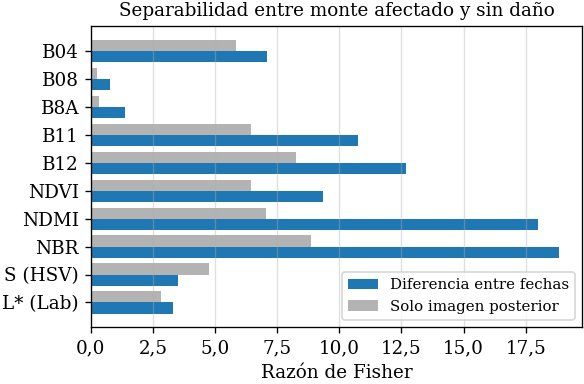

In [31]:
fig, ax = plt.subplots(figsize=(ancho(0.75), 3.2))
y = np.arange(len(tabla_sep))
ax.barh(y + 0.2, tabla_sep["Fisher diferencia"], 0.4, color="tab:blue", label="Diferencia entre fechas")
ax.barh(y - 0.2, tabla_sep["Fisher posterior"], 0.4, color="0.7", label="Solo imagen posterior")
ax.set_yticks(y, tabla_sep.index)
ax.invert_yaxis()
ax.set_xlabel("Razón de Fisher")
ax.grid(True, axis="x")
coma(ax, "x", 1)
ax.legend(fontsize=9, loc="lower right")
ax.set_title("Separabilidad entre monte afectado y sin daño")
guardar(fig, "separabilidad")
plt.show()

El índice que más separa es la diferencia del NBR, $dNBR = NBR_{pos} - NBR_{pre}$, con $NBR = (B8A - B12)/(B8A + B12)$. Usa el NIR, que baja con el daño, y el SWIR 2, que sube. La diferencia entre fechas separa el doble que la imagen posterior sola, porque descuenta lo que ya era distinto antes del tornado, como el relieve o los distintos tipos de monte. Los canales de color de la composición natural separan mucho menos, porque solo tienen información del visible.

Con la imagen posterior sola, además, el monte dañado se confunde con las chacras.

In [32]:
CHACRAS = [(200, 400, 50, 250)]
nbr_pos = variables["NBR"][1]
print("NBR posterior, monte afectado contra chacras: Fisher",
      round(fisher(muestras(nbr_pos, AFECTADO), muestras(nbr_pos, CHACRAS)), 2))

NBR posterior, monte afectado contra chacras: Fisher 0.09


**Composiciones.** Para el punto a se usa el color natural. Para el punto b no se usa una composición sino el dNBR, calculado sobre la reflectancia. Como referencia se muestra también la composición 12-8A-4 (SWIR 2, NIR y rojo), que usa las bandas del índice y donde el daño resalta mucho más que en color natural.

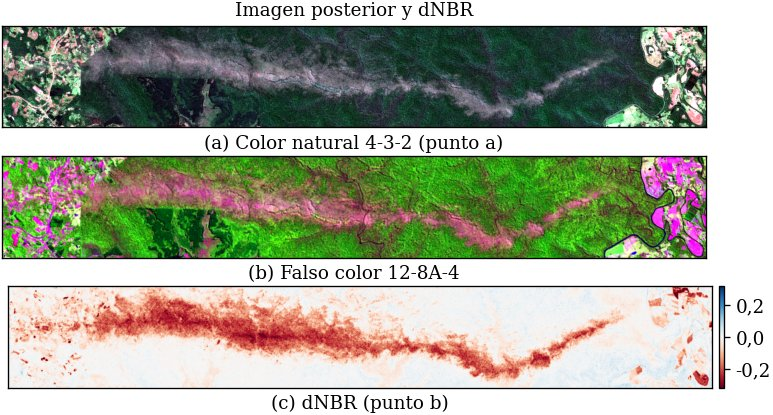

In [33]:
LIM_FALSO = {b: np.percentile(pre[b][valido], [2, 98]) for b in ("B12", "B8A", "B04")}
falso_pos = np.dstack([np.clip((pos[b] - LIM_FALSO[b][0]) / (LIM_FALSO[b][1] - LIM_FALSO[b][0]), 0, 1)
                       for b in ("B12", "B8A", "B04")])
dnbr = variables["NBR"][1] - variables["NBR"][0]
dnbr[~valido] = np.nan

fig, ax = plt.subplots(3, 1, figsize=(ancho(1.0), 3.45))
mostrar_img(ax[0], natural_pos[TRAZA], "a", "Color natural 4-3-2 (punto a)")
mostrar_img(ax[1], falso_pos[TRAZA], "b", "Falso color 12-8A-4")
im = mostrar_img(ax[2], dnbr[TRAZA], "c", "dNBR (punto b)", cmap="RdBu", norm=TwoSlopeNorm(0, -0.4, 0.4))
barra = fig.colorbar(im, ax=ax[2], fraction=0.03, pad=0.01)
barra.ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.1f}".replace(".", ",")))
ax[0].set_title("Imagen posterior y dNBR")
guardar(fig, "composiciones")
plt.show()

### Bitácora

| Decisión | Motivo | Criterio |
|---|---|---|
| Detectar con la diferencia entre fechas | Separa el doble que la imagen posterior sola y no confunde el daño con chacras | Razón de Fisher |
| Índice dNBR (B8A y B12) | Mayor separabilidad (Fisher 18,8 y solapamiento 0,01) | Razón de Fisher y solapamiento |
| Descartar el dNDVI | Separa la mitad que el dNBR | Razón de Fisher |
| Descartar los canales de color (HSV, Lab) | Solo tienen el visible y separan mucho menos | Razón de Fisher |
| No usar el azul ni el visible para medir el cambio | Cambian entre fechas por la atmósfera | Muestras sin daño |
| Composiciones distintas para a y b | El punto a busca que se entienda y el b busca separar | Pedido de la consigna y separabilidad |

## 6. Detección de cambios y umbral

Se probaron tres criterios para separar "afectado" de "no afectado" sobre el dNBR.

- **Otsu.** Umbral automático que separa las dos poblaciones del histograma.
- **Tres desvíos del monte estable.** La mediana menos tres desvíos. El desvío se estima con la mediana de las desviaciones absolutas (MAD), que casi no cambia por la traza. Marca todo cambio poco probable en una zona sin daño.
- **Muestras.** El umbral que deja menos errores entre las muestras de ajuste.

In [34]:
v = dnbr[valido]
mediana = np.median(v)
desvio = 1.4826 * np.median(np.abs(v - mediana))
dnbr_af, dnbr_sd = muestras(dnbr, AFECTADO), muestras(dnbr, SIN_DANO)
prueba = np.linspace(-0.5, 0.1, 601)
errores = [(dnbr_af >= t).mean() + (dnbr_sd < t).mean() for t in prueba]

UMBRALES = {"Otsu": float(threshold_otsu(v)),
            "Tres desvíos": float(mediana - 3 * desvio),
            "Muestras": float(prueba[int(np.argmin(errores))])}
print(f"Mediana {mediana:.4f}, desvío {desvio:.4f}")
for nombre, t in UMBRALES.items():
    print(f"{nombre:13s} {t:.3f}   píxeles por debajo {np.mean(v < t):.1%}")

Mediana 0.0030, desvío 0.0266
Otsu          -0.108   píxeles por debajo 6.8%
Tres desvíos  -0.077   píxeles por debajo 8.8%
Muestras      -0.069   píxeles por debajo 9.5%


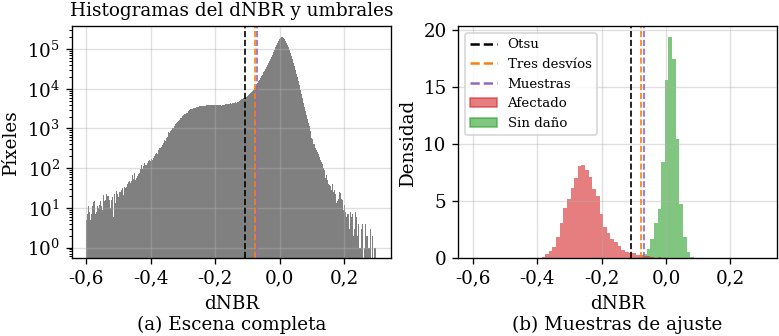

In [35]:
colores_umbral = {"Otsu": "k", "Tres desvíos": "tab:orange", "Muestras": "tab:purple"}
fig, ax = plt.subplots(1, 2, figsize=(ancho(1.0), 2.8))
ax[0].hist(v, bins=300, range=(-0.6, 0.3), color="0.5", log=True)
ax[1].hist(dnbr_sd, bins=80, range=(-0.6, 0.3), color="tab:green", alpha=0.6, density=True, label="Sin daño")
ax[1].hist(dnbr_af, bins=80, range=(-0.6, 0.3), color="tab:red", alpha=0.6, density=True, label="Afectado")
for a in ax:
    for nombre, t in UMBRALES.items():
        a.axvline(t, color=colores_umbral[nombre], ls="--", lw=1)
    a.grid(True)
    coma(a, "x", 1)
ax[0].set_ylabel("Píxeles")
ax[1].set_ylabel("Densidad")
ax[1].legend(handles=[Line2D([], [], color=c, ls="--", label=n) for n, c in colores_umbral.items()]
             + [Patch(color="tab:red", alpha=0.6, label="Afectado"), Patch(color="tab:green", alpha=0.6, label="Sin daño")],
             fontsize=8)
ax[0].set_xlabel("dNBR\n(a) Escena completa")
ax[1].set_xlabel("dNBR\n(b) Muestras de ajuste")
ax[0].set_title("Histogramas del dNBR y umbrales")
guardar(fig, "histograma_umbral")
plt.show()

El histograma de la escena tiene un pico en 0, que es todo lo que no cambió, y una meseta entre −0,35 y −0,1, que es el monte dañado. Otsu cae justo en el codo entre las dos, por eso se elige como criterio principal. Funciona porque la traza ocupa cerca del 5 % de la escena. El umbral de tres desvíos incluye además el daño leve de los bordes, así que se usa como límite superior. El de las muestras sale de rectángulos en el centro de la traza, donde el daño es fuerte, y da un valor parecido al de tres desvíos.

**Limpieza de la máscara.** Se hace en tres pasos.

1. **Apertura** con un disco de 3 × 3 píxeles, que quita píxeles sueltos.
2. **Se quitan las manchas** de menos de 50 píxeles (0,5 ha).
3. **Se conserva la traza.** Un cierre con un disco de 100 m de radio une los tramos de la traza, se toma la mayor mancha y se conservan las partes de la máscara que la tocan. Así quedan afuera los cambios de las chacras lejos de la traza, que en septiembre se deben a cosecha o preparación del suelo.

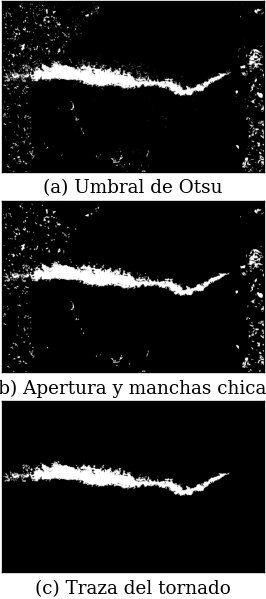

In [36]:
def quitar_chicas(m, minimo):
    etiquetas, _ = ndi.label(m)
    tam = np.bincount(etiquetas.ravel())
    conservar = tam >= minimo
    conservar[0] = False
    return conservar[etiquetas]


def mayor_mancha(m):
    etiquetas, _ = ndi.label(m)
    return etiquetas == np.argmax(np.bincount(etiquetas.ravel())[1:]) + 1


def mascara_afectada(umbral, pasos=False):
    cruda = (dnbr < umbral) & valido
    limpia = quitar_chicas(ndi.binary_opening(cruda, structure=disk(1)), 50)
    corredor = mayor_mancha(ndi.binary_closing(limpia, structure=disk(10)))
    etiquetas, _ = ndi.label(limpia)
    ids = np.unique(etiquetas[corredor & limpia])
    final = np.isin(etiquetas, ids[ids > 0])
    return (cruda, limpia, final) if pasos else final


cruda, limpia, afectada = mascara_afectada(UMBRALES["Otsu"], pasos=True)
fig, ax = plt.subplots(3, 1, figsize=(ancho(1.0), 5))
for a, m, letra, rotulo in zip(ax, (cruda, limpia, afectada), "abc",
                               ("Umbral de Otsu", "Apertura y manchas chicas", "Traza del tornado")):
    mostrar_img(a, m, letra, rotulo, cmap="gray")
plt.show()

**Validación.** Se mide qué parte de cada grupo de muestras de validación queda bien clasificada.

In [37]:
mascaras = {nombre: mascara_afectada(t) for nombre, t in UMBRALES.items()}
validacion = pd.DataFrame({nombre: {"Afectado detectado (%)": 100 * muestras(m, AFECTADO_VAL).mean(),
                                    "Sin daño no detectado (%)": 100 * (1 - muestras(m, SIN_DANO_VAL).mean())}
                           for nombre, m in mascaras.items()}).T.round(1)
validacion

,Afectado detectado (%),Sin daño no detectado (%)
Otsu,95.7,100.0
Tres desvíos,96.9,100.0
Muestras,97.1,100.0


### Bitácora

| Decisión | Motivo | Criterio |
|---|---|---|
| Umbral de Otsu como principal | Cae en el codo del histograma y el borde coincide con la franja visible | Histograma y visual |
| Tres desvíos como límite superior | Incluye el daño leve de los bordes | Histograma |
| Apertura de 3 × 3 y manchas mayores a 0,5 ha | Quita ruido y cambios puntuales | Visual |
| Conservar solo la traza | Los cambios de chacras lejos de la traza no son del tornado | Forma de las manchas |
| Validar con rectángulos distintos de los de ajuste | Evita medir sobre los mismos datos | Porcentaje de acierto |

## 7. Superficie afectada (punto b)

**Reserva.** No se cuenta con su límite oficial, así que se toma como reserva la mancha de monte continuo. Se marca como monte todo píxel con NDVI mayor a 0,75 en la imagen anterior. Se calcula la fracción de monte en una ventana de 500 m y se toma la mayor zona donde supera el 90 %, rellenando los claros interiores. La ventana corre el borde hacia adentro, por eso se dilata 120 m, lo que se midió sobre el borde recto del oeste.

**Área urbana.** Se usan los polígonos de Tobuna y Cruce Caballero de OpenStreetMap. También se incluye la comunidad Kurupayty, que está dentro del monte.

**Rural.** Es todo lo que no es reserva ni área urbana, sobre todo chacras.

In [38]:
ndvi_pre = variables["NDVI"][0]
monte = (ndvi_pre > 0.75) & valido
fraccion = ndi.uniform_filter(monte.astype(np.float32), 51)
reserva = ndi.binary_dilation(ndi.binary_fill_holes(mayor_mancha(fraccion > 0.9)), structure=disk(12))
print(f"Reserva estimada: {superficie(reserva):.1f} km²")

Reserva estimada: 299.6 km²


In [39]:
OSM_IDS = {"Tobuna": ("relation", 11569571), "Cruce Caballero": ("relation", 11571723),
           "Comunidad Kurupayty": ("way", 1313013770)}


def cargar_osm():
    archivo = DIR_DATOS / "osm_urbano.json"
    if not archivo.exists():
        consulta = "[out:json][timeout:90];(" + "".join(f"{t}({i});" for t, i in OSM_IDS.values()) + ");out geom;"
        pedido = urllib.request.Request("https://overpass-api.de/api/interpreter",
                                        data=urllib.parse.urlencode({"data": consulta}).encode(),
                                        headers={"User-Agent": "FDPI-UNaM"})
        archivo.write_bytes(urllib.request.urlopen(pedido, timeout=120).read())
    return json.loads(archivo.read_text(encoding="utf-8"))


def a_pixeles(geometria):
    # lon, lat a columna, fila (centro del píxel)
    return np.array([[(p["lon"] - LON0) / DLON - 0.5, (LAT0 - p["lat"]) / DLAT - 0.5] for p in geometria])


osm = {e["id"]: e for e in cargar_osm()["elements"]}
urbanos = {}
for nombre, (tipo, i) in OSM_IDS.items():
    e = osm[i]
    anillos = [e["geometry"]] if tipo == "way" else [m["geometry"] for m in e["members"] if m.get("role") == "outer"]
    m = np.zeros((H, W), np.uint8)
    for g in anillos:
        cv2.fillPoly(m, [np.round(a_pixeles(g) * 16).astype(np.int32)], 1, shift=4)
    urbanos[nombre] = m.astype(bool)
urbano = np.any(list(urbanos.values()), axis=0)
for nombre, m in urbanos.items():
    print(f"{nombre}: {superficie(m):.2f} km²")

Tobuna: 0.47 km²
Cruce Caballero: 0.54 km²
Comunidad Kurupayty: 0.00 km²


In [40]:
def por_zona(m):
    return {"Reserva": superficie(m & reserva), "Urbana": superficie(m & urbano),
            "Rural": superficie(m & ~reserva & ~urbano), "Total": superficie(m)}


casos = {f"Umbral {nombre.lower()}": m for nombre, m in mascaras.items()}
casos["Otsu, borde −1 px"] = ndi.binary_erosion(mascaras["Otsu"])
casos["Otsu, borde +1 px"] = ndi.binary_dilation(mascaras["Otsu"])
casos["Tres desvíos, borde +1 px"] = ndi.binary_dilation(mascaras["Tres desvíos"])
tabla_area = pd.DataFrame({k: por_zona(m) for k, m in casos.items()}).T.round(2)
tabla_area

,Reserva,Urbana,Rural,Total
Umbral otsu,18.19,0.0,1.08,19.27
Umbral tres desvíos,20.77,0.0,1.90,22.67
Umbral muestras,21.47,0.0,2.18,23.66
"Otsu, borde −1 px",17.00,0.0,0.79,17.79
"Otsu, borde +1 px",19.28,0.0,1.37,20.65
"Tres desvíos, borde +1 px",21.98,0.0,2.35,24.33


**Cota de incertidumbre.** Hay dos fuentes principales.

- **El umbral.** Pasar de Otsu a tres desvíos agrega el daño leve de los bordes.
- **El borde.** Los píxeles del borde mezclan monte sano y dañado, y el NIR y el SWIR 2 se miden a 20 m. Se toma un píxel de más o de menos en todo el contorno.

El valor central es el de Otsu. El mínimo es la máscara de Otsu con un píxel menos de borde y el máximo es la de tres desvíos con un píxel más.

In [41]:
central = tabla_area.loc["Umbral otsu"]
minimo = tabla_area.loc["Otsu, borde −1 px"]
maximo = tabla_area.loc["Tres desvíos, borde +1 px"]
resumen = pd.DataFrame({"Central": central, "Mínimo": minimo, "Máximo": maximo}).round(2)
resumen

,Central,Mínimo,Máximo
Reserva,18.19,17.00,21.98
Urbana,0.00,0.00,0.00
Rural,1.08,0.79,2.35
Total,19.27,17.79,24.33


In [42]:
# Distancia de cada área urbana a la traza
dist = ndi.distance_transform_edt(~mascaras["Otsu"], sampling=(DY.mean(), DX.mean()))
for nombre, m in urbanos.items():
    print(f"{nombre}: {dist[m].min():,.0f} m de la traza".replace(",", "."))

# Largo en sentido oeste-este y ancho medio
columnas = np.where(mascaras["Otsu"].any(axis=0))[0]
largo = (columnas[-1] - columnas[0] + 1) * DX.mean() / 1000
print(f"Largo oeste-este: {largo:.1f} km. Ancho medio: {central['Total'] / largo * 1000:.0f} m")
print(f"La traza llega a {columnas[0]} px del borde oeste de la imagen")

Tobuna: 4.585 m de la traza
Cruce Caballero: 858 m de la traza
Comunidad Kurupayty: 14 m de la traza
Largo oeste-este: 21.7 km. Ancho medio: 887 m
La traza llega a 11 px del borde oeste de la imagen


### Bitácora

| Decisión | Motivo | Criterio |
|---|---|---|
| Reserva como monte continuo | No hay límite oficial disponible | Fracción de monte en 500 m y visual |
| Dilatar la reserva 120 m | La ventana corre el borde hacia adentro | Borde recto del oeste |
| Área urbana de OpenStreetMap | Es una referencia independiente de la imagen | Polígonos de Tobuna, Cruce Caballero y Kurupayty |
| Área del píxel según la latitud | El píxel mide 100,6 m² y no 100 m² | Elipsoide WGS 84 |
| Cota entre Otsu con −1 px y tres desvíos con +1 px | Junta la incertidumbre del umbral y la del borde | Tabla de áreas |

## 8. Mapa del área afectada

Máscara de Otsu sobre la imagen posterior en color natural (la del punto a), con leyenda, escala y orientación.

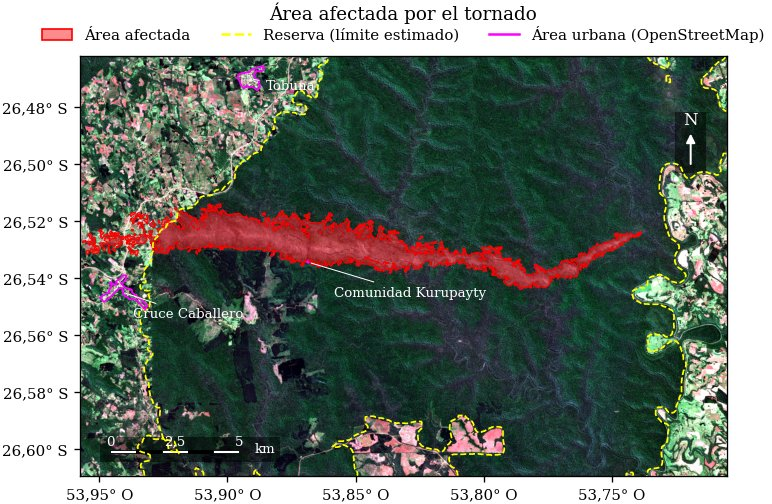

In [43]:
extension = (LON0, LON0 + W * DLON, LAT0 - H * DLAT, LAT0)
lat_media = LAT0 - H * DLAT / 2
relacion = np.interp(lat_media, lat_fila[::-1], (m_lat / m_lon)[::-1])   # para que 1 km mida lo mismo en x y en y


def grados(v, eje):
    return f"{abs(v):.2f}° {'O' if eje == 'x' else 'S'}".replace(".", ",")


capa = np.zeros((H, W, 4))
capa[mascaras["Otsu"]] = (1, 0, 0, 0.45)

fig, ax = plt.subplots(figsize=(ancho(1.0), 5.2))
ax.imshow(natural_pos, extent=extension)
ax.imshow(capa, extent=extension)
y_px, x_px = np.mgrid[0:H, 0:W]
lon_px, lat_px = LON0 + (x_px + 0.5) * DLON, LAT0 - (y_px + 0.5) * DLAT
ax.contour(lon_px, lat_px, mascaras["Otsu"], [0.5], colors="red", linewidths=0.6)
ax.contour(lon_px, lat_px, reserva, [0.5], colors="yellow", linewidths=1, linestyles="--")
ax.contour(lon_px, lat_px, urbano, [0.5], colors="magenta", linewidths=1)
ax.set_aspect(relacion)

for nombre, (dlon, dlat) in {"Tobuna": (0.006, -0.004), "Cruce Caballero": (0.004, -0.009),
                             "Comunidad Kurupayty": (0.01, -0.012)}.items():
    f, c = np.argwhere(urbanos[nombre]).mean(axis=0)
    lon, lat = LON0 + (c + 0.5) * DLON, LAT0 - (f + 0.5) * DLAT
    ax.annotate(nombre, (lon, lat), (lon + dlon, lat + dlat), color="white", fontsize=8,
                arrowprops={"arrowstyle": "-", "color": "white", "lw": 0.6})

# Escala de 5 km
km_lon = 1000 / np.interp(lat_media, lat_fila[::-1], m_lon[::-1])
x0, y0 = LON0 + 0.012, LAT0 - H * DLAT + 0.008
ax.add_patch(Rectangle((x0 - 0.004, y0 - 0.003), 6.6 * km_lon + 0.004, 0.0085, fc="black", alpha=0.5, lw=0))
for i, color in enumerate(("white", "black", "white", "black", "white")):
    ax.add_patch(Rectangle((x0 + i * km_lon, y0), km_lon, 0.0012, fc=color, ec="black", lw=0.5))
for km in (0, 2.5, 5):
    ax.text(x0 + km * km_lon, y0 + 0.0027, f"{km:g}".replace(".", ","), color="white", fontsize=8, ha="center")
ax.text(x0 + 5.6 * km_lon, y0 + 0.0002, "km", color="white", fontsize=8)

# Norte
xn, yn = LON0 + W * DLON - 0.014, LAT0 - 0.022
ax.add_patch(Rectangle((xn - 0.006, yn - 0.019), 0.012, 0.0215, fc="black", alpha=0.5, lw=0))
ax.annotate("", (xn, yn - 0.004), (xn, yn - 0.017), arrowprops={"arrowstyle": "-|>", "color": "white", "lw": 1.2})
ax.text(xn, yn - 0.0035, "N", color="white", fontsize=10, ha="center", va="bottom")

ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: grados(v, "x")))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: grados(v, "y")))
ax.tick_params(labelsize=9)
ax.legend(handles=[Patch(fc=(1, 0, 0, 0.45), ec="red", label="Área afectada"),
                   Line2D([], [], color="yellow", ls="--", label="Reserva (límite estimado)"),
                   Line2D([], [], color="magenta", label="Área urbana (OpenStreetMap)")],
          loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False, fontsize=9)
ax.set_title("Área afectada por el tornado", pad=22)
guardar(fig, "mapa_afectado")
plt.show()

Detalle de la comunidad Kurupayty, que queda al borde de la traza.

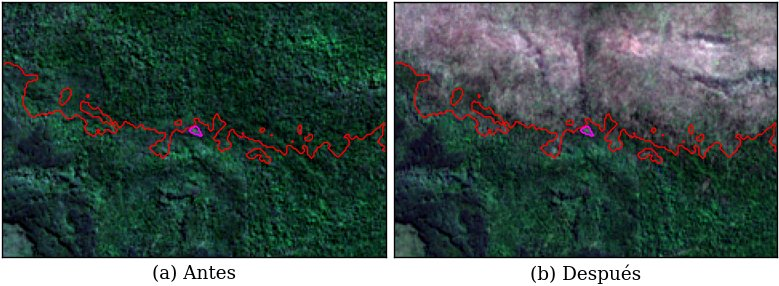

In [44]:
f, c = np.argwhere(urbanos["Comunidad Kurupayty"]).mean(axis=0).astype(int)
detalle = np.s_[f - 80:f + 80, c - 120:c + 120]
fig, ax = plt.subplots(1, 2, figsize=(ancho(1.0), 2.4))
for a, img, letra, rotulo in ((ax[0], natural_pre, "a", "Antes"), (ax[1], natural_pos, "b", "Después")):
    mostrar_img(a, img[detalle], letra, rotulo)
    a.contour(mascaras["Otsu"][detalle], [0.5], colors="red", linewidths=0.8)
    a.contour(urbanos["Comunidad Kurupayty"][detalle], [0.5], colors="magenta", linewidths=1)
plt.show()

## 9. Resumen

In [45]:
print(f"Superficie afectada: {central['Total']:.1f} km² (entre {minimo['Total']:.1f} y {maximo['Total']:.1f} km²)".replace(".", ","))
for zona in ("Reserva", "Rural", "Urbana"):
    print(f"  {zona}: {central[zona]:.2f} km² (entre {minimo[zona]:.2f} y {maximo[zona]:.2f})".replace(".", ","))

Superficie afectada: 19,3 km² (entre 17,8 y 24,3 km²)
  Reserva: 18,19 km² (entre 17,00 y 21,98)
  Rural: 1,08 km² (entre 0,79 y 2,35)
  Urbana: 0,00 km² (entre 0,00 y 0,00)
